# Hair and clothing mask: GPU smoke test

This small test checks that the project Python environment can run a mask-based
color edit on a PSC GPU. It uses a synthetic image and masks; it does **not**
download CelebAMask-HQ or model weights and is **not** our B0, B1, or LoRA method.
Run it inside a Slurm GPU allocation.

In [1]:
import os
import socket

import torch
from IPython.display import display
from PIL import Image

assert os.environ.get("SLURM_JOB_ID"), "Run this notebook in a Slurm GPU job."
assert torch.cuda.is_available(), "No CUDA GPU is visible in this kernel."
device = torch.device("cuda:0")
print("Slurm job:", os.environ["SLURM_JOB_ID"])
print("Compute node:", socket.gethostname())
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__, "| CUDA build:", torch.version.cuda)

Slurm job: 49438611
Compute node: v020.ib.bridges2.psc.edu
GPU: Tesla V100-SXM2-32GB
PyTorch: 2.6.0+cu118 | CUDA build: 11.8


We make a tiny portrait-like image on the GPU. The hair and clothing masks
stand in for the regions our project will eventually obtain from dataset masks.

In [2]:
height = width = 128
y, x = torch.meshgrid(
    torch.arange(height, device=device),
    torch.arange(width, device=device),
    indexing="ij",
)
face_mask = ((x - 64) / 27) ** 2 + ((y - 66) / 32) ** 2 <= 1
hair_mask = ((((x - 64) / 34) ** 2 + ((y - 45) / 24) ** 2) <= 1) & (y < 58)
cloth_mask = (y >= 96) & (torch.abs(x - 64) <= 42)

shade = (0.7 + 0.3 * x.float() / (width - 1)).unsqueeze(-1)
original = torch.full((height, width, 3), 0.90, device=device)
original[face_mask] = torch.tensor([0.82, 0.60, 0.46], device=device)
original[hair_mask] = torch.tensor([0.29, 0.16, 0.10], device=device) * shade[hair_mask]
original[cloth_mask] = torch.tensor([0.16, 0.32, 0.66], device=device) * shade[cloth_mask]

# Example target colors associated with our hair / clothing editing task.
target_hair = torch.tensor([0.87, 0.13, 0.14], device=device)   # red
target_cloth = torch.tensor([0.10, 0.70, 0.28], device=device)  # green
edited = original.clone()
edited[hair_mask] = target_hair * shade[hair_mask]
edited[cloth_mask] = target_cloth * shade[cloth_mask]

In [3]:
torch.cuda.synchronize()
union_mask = hair_mask | cloth_mask
assert original.is_cuda and edited.is_cuda and union_mask.is_cuda
assert torch.equal(original[~union_mask], edited[~union_mask]), "Pixels outside masks changed."
assert torch.any(original[hair_mask] != edited[hair_mask]), "Hair was not edited."
assert torch.any(original[cloth_mask] != edited[cloth_mask]), "Clothing was not edited."
print("Image and edits ran on:", edited.device)
print("Hair pixels:", hair_mask.sum().item(), "| Clothing pixels:", cloth_mask.sum().item())
print("Outside-mask pixels changed:", torch.count_nonzero(original[~union_mask] - edited[~union_mask]).item())
print("Peak CUDA memory (MiB):", round(torch.cuda.max_memory_allocated() / 1024**2, 2))
print("GPU smoke test: PASS")

Image and edits ran on: cuda:0
Hair pixels: 2083 | Clothing pixels: 2720
Outside-mask pixels changed: 0
Peak CUDA memory (MiB): 0.96
GPU smoke test: PASS


Left: original | Middle: hair (red) and clothing (blue) masks | Right: edited


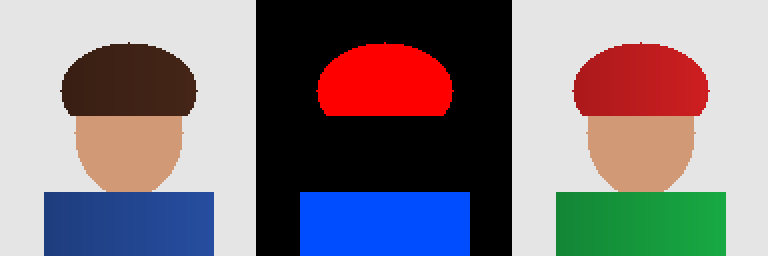

In [4]:
# Move tensors to CPU only for displaying the result.
def as_image(tensor):
    pixels = (tensor.clamp(0, 1) * 255).to(torch.uint8).cpu().numpy()
    return Image.fromarray(pixels, mode="RGB")

mask_view = torch.zeros_like(original)
mask_view[hair_mask] = torch.tensor([1.0, 0.0, 0.0], device=device)
mask_view[cloth_mask] = torch.tensor([0.0, 0.3, 1.0], device=device)
panel = Image.new("RGB", (width * 3, height))
for index, tensor in enumerate((original, mask_view, edited)):
    panel.paste(as_image(tensor), (index * width, 0))
print("Left: original | Middle: hair (red) and clothing (blue) masks | Right: edited")
display(panel.resize((width * 6, height * 2), Image.Resampling.NEAREST))